# Airline Ticket Price Prediction — Final Colab Notebook

*

## Import libraries

In [ ]:
import pandas as pd
import numpy as np

## Load the airline dataset

In [ ]:
from google.colab import files

uploaded = files.upload()  # Choose the airline CSV file
file_name = list(uploaded.keys())[0]

df = pd.read_csv(file_name)

print("Rows and columns:", df.shape)
print(df.head())

Saving airline_flights_dataset_3lakh.csv to airline_flights_dataset_3lakh.csv
Rows and columns: (300000, 11)
              airline   flight source_city departure_time stops arrival_time  \
0             Vistara  UK-5368     Kolkata        Morning   one      Evening   
1        Thai_Airways  TG-2192     Bangkok  Early_Morning   one    Afternoon   
2              IndiGo  6E-2766       Delhi        Morning  zero    Afternoon   
3  Singapore_Airlines  SQ-7307         Goa  Early_Morning   one        Night   
4     British_Airways  BA-5039      London        Morning   one   Late_Night   

  destination_city     class  duration  days_left  price  
0          Lucknow  Business      7.55         16  20596  
1            Delhi   Economy      8.48          9  23965  
2           Mumbai   Economy      2.45         14   6848  
3           Sydney   Economy     15.81         28  48816  
4              Goa   Economy     16.55         25  51251  


##  — Data cleaning and descriptive statistics

In [ ]:
# See missing values and duplicate rows
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows where ticket price is missing
df = df.dropna(subset=["price"])

# Basic statistics for ticket price
print("Mean:", df["price"].mean())
print("Median:", df["price"].median())
print("Mode:", df["price"].mode()[0])
print("Variance:", df["price"].var())
print("Standard deviation:", df["price"].std())
print("Quartiles:")
print(df["price"].quantile([0.25, 0.50, 0.75]))

# Summary statistics
print(df.describe())

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64
Duplicate rows: 0
Mean: 22411.22532
Median: 8019.0
Mode: 5177
Variance: 1122809940.6678953
Standard deviation: 33508.35628120089
Quartiles:
0.25     5432.0
0.50     8019.0
0.75    24187.0
Name: price, dtype: float64
            duration      days_left          price
count  300000.000000  300000.000000  300000.000000
mean        6.278159      24.992073   22411.225320
std         4.301640      14.161850   33508.356281
min         0.600000       1.000000    2118.000000
25%         3.110000      13.000000    5432.000000
50%         5.410000      25.000000    8019.000000
75%         7.810000      37.000000   24187.000000
max        32.220000      49.000000  380157.000000


##  — Data visualization

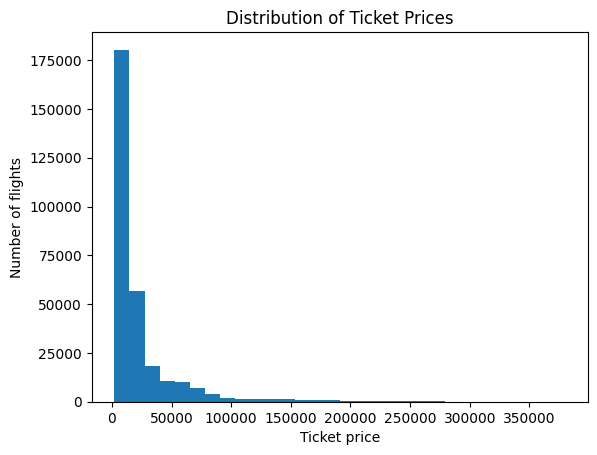

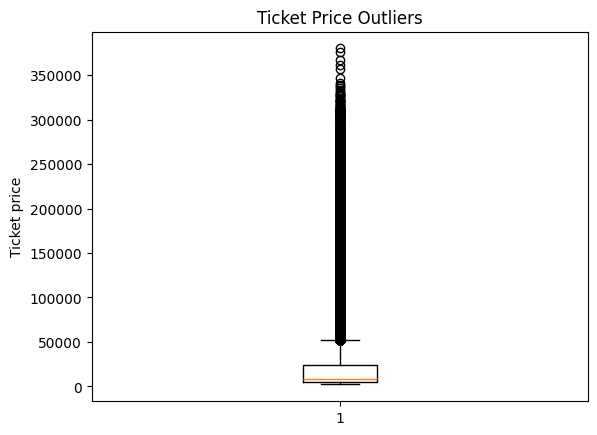

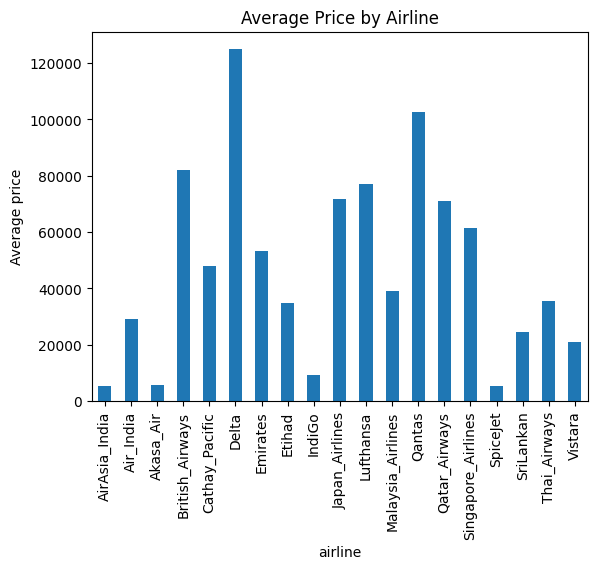

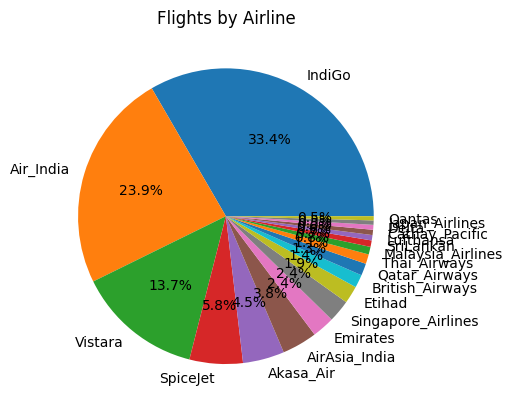

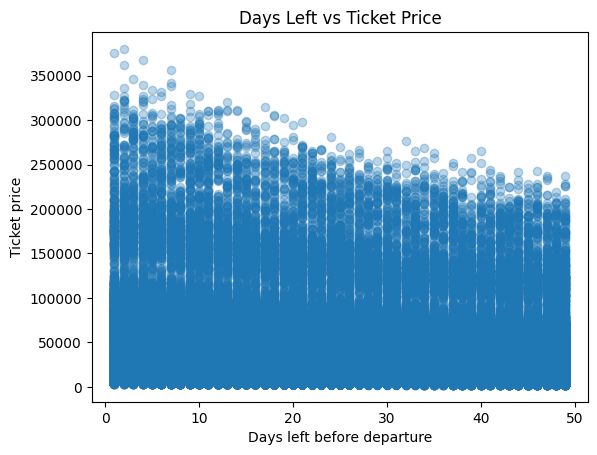

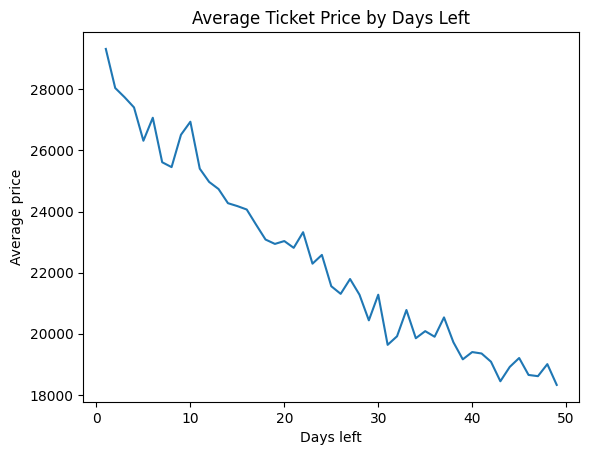

In [ ]:
import matplotlib.pyplot as plt

# 1. Histogram
plt.hist(df["price"], bins=30)
plt.title("Distribution of Ticket Prices")
plt.xlabel("Ticket price")
plt.ylabel("Number of flights")
plt.show()

# 2. Box plot
plt.boxplot(df["price"])
plt.title("Ticket Price Outliers")
plt.ylabel("Ticket price")
plt.show()

# 3. Bar chart: average price by airline
df.groupby("airline")["price"].mean().plot(kind="bar")
plt.title("Average Price by Airline")
plt.ylabel("Average price")
plt.show()

# 4. Pie chart: number of flights by airline
df["airline"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Flights by Airline")
plt.ylabel("")
plt.show()

# 5. Scatter plot: days left vs price
plt.scatter(df["days_left"], df["price"], alpha=0.3)
plt.title("Days Left vs Ticket Price")
plt.xlabel("Days left before departure")
plt.ylabel("Ticket price")
plt.show()

# 6. Line chart: average price by days left
df.groupby("days_left")["price"].mean().sort_index().plot(kind="line")
plt.title("Average Ticket Price by Days Left")
plt.xlabel("Days left")
plt.ylabel("Average price")
plt.show()

## — Probability and sampling

Probability price is above the mean: 0.27896666666666664
                  airline  price
205179      AirAsia_India   2831
101710  Malaysia_Airlines  30407
89106              Etihad  16335
193046             IndiGo   5150
99093           Air_India  41117
105506             IndiGo   6419
298780             IndiGo   3273
44748              IndiGo   8647
288650            Vistara   4905
55207     British_Airways  46193


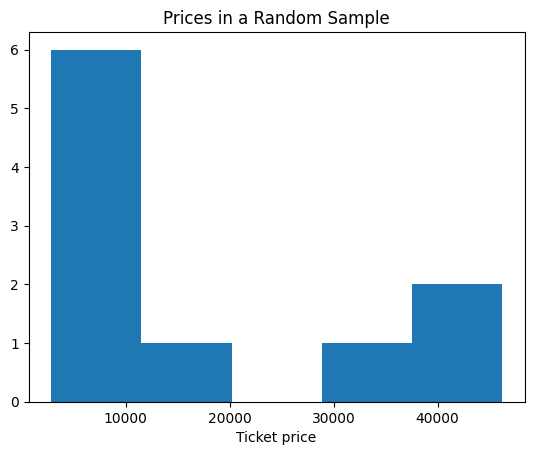

In [ ]:
import numpy as np

# Probability that a randomly selected ticket costs more than the mean
mean_price = df["price"].mean()
probability = (df["price"] > mean_price).mean()
print("Probability price is above the mean:", probability)

# Random sample of 10 flights
random_sample = df.sample(n=10, random_state=1)
print(random_sample[["airline", "price"]])

# Sample ticket prices and view their distribution
plt.hist(random_sample["price"], bins=5)
plt.title("Prices in a Random Sample")
plt.xlabel("Ticket price")
plt.show()

##  — Central Limit Theorem and point estimation

Population mean estimate: 22411.22532
Mean of sample means: 22334.574666666667


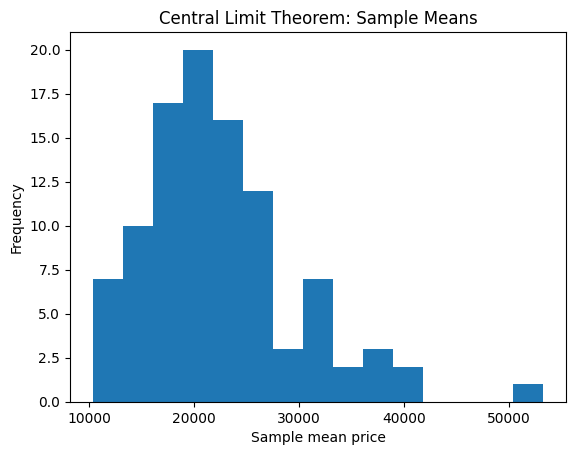

In [ ]:
# Take 100 samples and calculate each sample's mean price
sample_means = []

for i in range(100):
    sample = df["price"].sample(n=30, replace=True, random_state=i)
    sample_means.append(sample.mean())

print("Population mean estimate:", df["price"].mean())
print("Mean of sample means:", np.mean(sample_means))

plt.hist(sample_means, bins=15)
plt.title("Central Limit Theorem: Sample Means")
plt.xlabel("Sample mean price")
plt.ylabel("Frequency")
plt.show()

##  — T-test
We compare ticket prices for nonstop and connecting flights. The code checks the dataset's `stops` values and assumes `zero` means nonstop, as in the common Kaggle dataset.

In [ ]:
from scipy.stats import ttest_ind

print(df["stops"].value_counts())

# Separate nonstop and connecting flight prices
nonstop = df[df["stops"].astype(str).str.lower() == "zero"]["price"]
connecting = df[df["stops"].astype(str).str.lower() != "zero"]["price"]

# Welch's independent t-test
t_value, p_value = ttest_ind(nonstop, connecting, equal_var=False)

print("Average nonstop price:", nonstop.mean())
print("Average connecting price:", connecting.mean())
print("T statistic:", t_value)
print("P value:", p_value)

if p_value < 0.05:
    print("There is a statistically significant difference in average prices.")
else:
    print("There is not enough evidence of a difference in average prices.")

stops
one            159722
zero           124009
two_or_more     16269
Name: count, dtype: int64
Average nonstop price: 22433.337443250086
Average connecting price: 22395.64439658846
T statistic: 0.30814968336648835
P value: 0.7579686661325442
There is not enough evidence of a difference in average prices.


##   — Model Comparison: Predicting Ticket Price

The user enters four details: **source city, destination city, class (Economy or Business) and days left before departure** (how early the ticket is booked). The target is the ticket **price**.

Cities are text, so the notebook converts the two cities into numbers a model can use: the **distance between them in km** and whether the flight is **international**. Class is converted with **One-Hot Encoding**. A pipeline keeps the preprocessing and model together.

We train **three different models** on the same data and compare them:
- **Decision Tree** — a single tree of if/else rules.
- **Random Forest** — many decision trees, predictions averaged.
- **Gradient Boosting** — trees built one after another, each fixing the errors of the previous ones.

The best model (highest R² score on the test data) is used in the Streamlit app.

### City information and distance
This cell writes a small helper file, `route_features.py`. It stores the position of each city and calculates the distance between two cities. The Streamlit app uses the same file.

In [ ]:
%%writefile route_features.py

import numpy as np

# (latitude, longitude, country) of every city in the dataset
city_info = {
    "Delhi": (28.61, 77.21, "India"),
    "Mumbai": (19.08, 72.88, "India"),
    "Bangalore": (12.97, 77.59, "India"),
    "Hyderabad": (17.39, 78.49, "India"),
    "Chennai": (13.08, 80.27, "India"),
    "Kolkata": (22.57, 88.36, "India"),
    "Pune": (18.52, 73.86, "India"),
    "Ahmedabad": (23.02, 72.57, "India"),
    "Goa": (15.38, 73.83, "India"),
    "Jaipur": (26.91, 75.79, "India"),
    "Kochi": (9.93, 76.27, "India"),
    "Lucknow": (26.85, 80.95, "India"),
    "Nagpur": (21.15, 79.09, "India"),
    "Guwahati": (26.14, 91.74, "India"),
    "Chandigarh": (30.73, 76.78, "India"),
    "Bhubaneswar": (20.3, 85.82, "India"),
    "Dubai": (25.2, 55.27, "UAE"),
    "Singapore": (1.35, 103.82, "Singapore"),
    "London": (51.47, -0.45, "UK"),
    "Bangkok": (13.69, 100.75, "Thailand"),
    "Kuala_Lumpur": (2.75, 101.71, "Malaysia"),
    "Doha": (25.27, 51.61, "Qatar"),
    "Colombo": (7.18, 79.88, "Sri Lanka"),
    "New_York": (40.64, -73.78, "USA"),
    "Sydney": (-33.94, 151.18, "Australia"),
    "Tokyo": (35.55, 139.78, "Japan"),
    "Hong_Kong": (22.31, 113.91, "Hong Kong"),
    "Frankfurt": (50.04, 8.57, "Germany"),
}

def add_route_features(data):
    """Add distance_km and is_international using source_city and destination_city."""
    data = data.copy()
    lat1 = np.radians(data["source_city"].map(lambda c: city_info[c][0]).astype(float))
    lon1 = np.radians(data["source_city"].map(lambda c: city_info[c][1]).astype(float))
    lat2 = np.radians(data["destination_city"].map(lambda c: city_info[c][0]).astype(float))
    lon2 = np.radians(data["destination_city"].map(lambda c: city_info[c][1]).astype(float))

    # Haversine formula: distance between two points on the earth (km)
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    data["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

    # 1 if the two cities are in different countries, otherwise 0
    country1 = data["source_city"].map(lambda c: city_info[c][2])
    country2 = data["destination_city"].map(lambda c: city_info[c][2])
    data["is_international"] = (country1 != country2).astype(int)
    return data

Writing route_features.py


### Prepare the data

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from route_features import city_info, add_route_features

# Columns the user enters: source_city, destination_city, class, days_left
missing_columns = [col for col in ["source_city", "destination_city", "class", "days_left", "price"]
                   if col not in df.columns]
if missing_columns:
    raise ValueError("Missing required column(s): " + ", ".join(missing_columns))

# Every city in the dataset must be listed in route_features.py
cities_in_data = set(df["source_city"].astype(str).str.strip()) | set(df["destination_city"].astype(str).str.strip())
unknown_cities = sorted(cities_in_data - set(city_info))
if unknown_cities:
    raise ValueError("Add these cities to city_info in route_features.py: " + ", ".join(unknown_cities))

# Prepare a clean dataset for the model
model_data = df[["source_city", "destination_city", "class", "days_left", "price"]].copy()
model_data["days_left"] = pd.to_numeric(model_data["days_left"], errors="coerce")
model_data["price"] = pd.to_numeric(model_data["price"], errors="coerce")
for col in ["source_city", "destination_city", "class"]:
    model_data[col] = model_data[col].astype("string").str.strip()
model_data = model_data.dropna()

# Add distance between the two cities and international flag
model_data = add_route_features(model_data)

# Input columns (X) and target column (y)
numeric_features = ["days_left", "distance_km", "is_international"]
text_features = ["class"]

X = model_data[numeric_features + text_features]
y = model_data["price"]

# Fill missing values and convert class with One-Hot Encoding
preprocessor = ColumnTransformer(transformers=[
    ("numbers", SimpleImputer(strategy="median"), numeric_features),
    ("text", Pipeline(steps=[
        ("fill_missing_text", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"))
    ]), text_features)
])

# Split data into training and testing parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Rows used for model:", len(model_data))
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
model_data[["source_city", "destination_city", "class", "days_left", "distance_km", "is_international", "price"]].head()

Rows used for model: 300000
Training rows: 240000 | Testing rows: 60000


,source_city,destination_city,class,days_left,distance_km,is_international,price
0,Kolkata,Lucknow,Business,16,886.677809,0,20596
1,Bangkok,Delhi,Economy,9,2941.379048,1,23965
2,Delhi,Mumbai,Economy,14,1147.233337,0,6848
3,Goa,Sydney,Economy,28,9834.880444,1,48816
4,London,Goa,Economy,25,7591.468630,1,51251


### Train the three models

In [ ]:
# Three models to compare
models = {
    "Decision Tree": DecisionTreeRegressor(max_depth=20, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=18, min_samples_leaf=10,
                                           n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, max_depth=5, random_state=42),
}

trained_models = {}
all_predictions = {}
result_rows = []

for name, regressor in models.items():
    # Same preprocessing for every model, then the model itself
    pipe = Pipeline(steps=[
        ("preprocessing", clone(preprocessor)),
        ("regression", regressor)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)

    trained_models[name] = pipe
    all_predictions[name] = pred
    result_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 score": r2_score(y_test, pred),
        "Accuracy (%)": max(0, r2_score(y_test, pred)) * 100,
    })
    print(name, "trained")

Decision Tree trained
Random Forest trained
Gradient Boosting trained


### Compare the models

In [ ]:
results_df = pd.DataFrame(result_rows).sort_values("R2 score", ascending=False).reset_index(drop=True)
results_df = results_df.round(3)
print(results_df)

best_model_name = results_df.loc[0, "Model"]
print("\nBest model (highest R2 score):", best_model_name)
print("Accuracy of best model:", results_df.loc[0, "Accuracy (%)"], "%  (Accuracy = R2 score x 100)")

               Model       MAE      RMSE  R2 score  Accuracy (%)
0  Gradient Boosting  1877.688  4123.470     0.985        98.492
1      Random Forest  1902.776  4168.375     0.985        98.459
2      Decision Tree  1915.578  4210.876     0.984        98.427

Best model (highest R2 score): Gradient Boosting
Accuracy of best model: 98.492 %  (Accuracy = R2 score x 100)


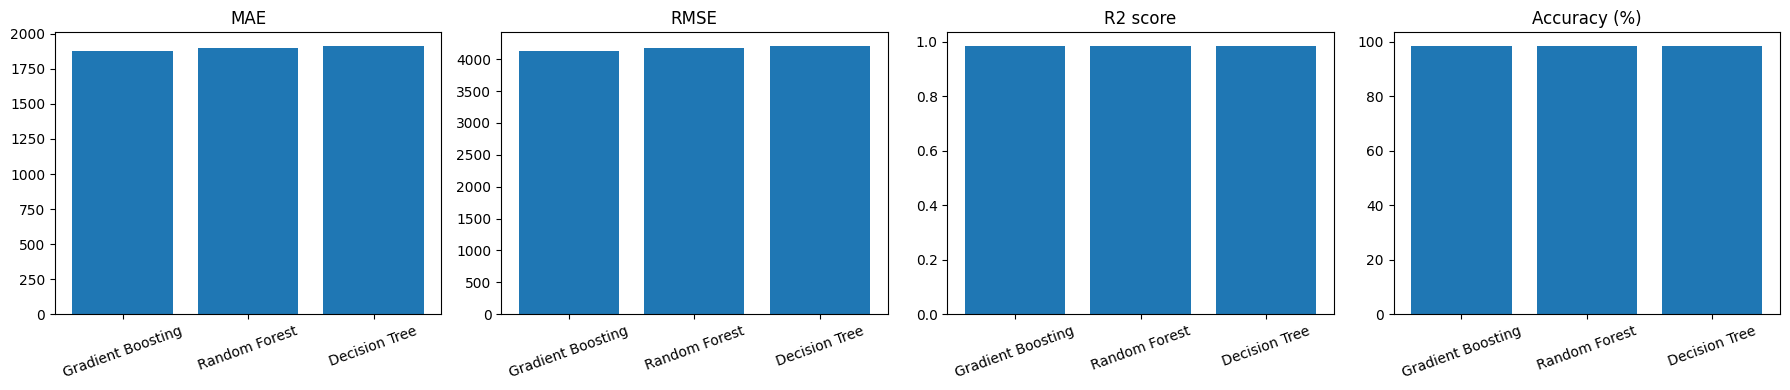

In [ ]:
# Bar charts: lower MAE / RMSE and higher R2 / Accuracy are better
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 score", "Accuracy (%)"]):
    ax.bar(results_df["Model"], results_df[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### Best model: actual vs predicted prices

In [ ]:
# Use the best model for the rest of the notebook and the app
model = trained_models[best_model_name]
predictions = all_predictions[best_model_name]

results = pd.DataFrame({"Actual price": y_test.values, "Predicted price": predictions})
print(results.head())

   Actual price  Predicted price
0          7933      6914.407358
1         15581     14456.114364
2         35801     43584.334859
3         65468     65502.315637
4         16145     16045.485343


In [ ]:
import joblib

# Save all trained models and the details the app needs
all_cities = sorted(set(model_data["source_city"].astype(str)) | set(model_data["destination_city"].astype(str)))

joblib.dump({
    "models": trained_models,
    "results": results_df.to_dict("records"),
    "best": best_model_name,
    "cities": all_cities,
    "classes": sorted(model_data["class"].astype(str).unique().tolist()),
}, "airline_model.pkl", compress=3)

print("Models saved as airline_model.pkl")
print("Cities saved:", len(all_cities))
print(all_cities)

Models saved as airline_model.pkl
Cities saved: 28
['Ahmedabad', 'Bangalore', 'Bangkok', 'Bhubaneswar', 'Chandigarh', 'Chennai', 'Colombo', 'Delhi', 'Doha', 'Dubai', 'Frankfurt', 'Goa', 'Guwahati', 'Hong_Kong', 'Hyderabad', 'Jaipur', 'Kochi', 'Kolkata', 'Kuala_Lumpur', 'London', 'Lucknow', 'Mumbai', 'Nagpur', 'New_York', 'Pune', 'Singapore', 'Sydney', 'Tokyo']


##  — Streamlit prediction interface

The app loads the saved models, shows the model comparison, and predicts the ticket price for the **source city, destination city, class (Economy or Business) and days before departure** entered by the user. It is written to `app.py` in small pieces (the first cell creates the file, the next cells add to it).

In [ ]:
!pip -q install streamlit scikit-learn pandas numpy joblib

### Streamlit app — part 1: load the model

In [ ]:
%%writefile app.py

import os
import joblib
import pandas as pd
import streamlit as st

from route_features import add_route_features

st.set_page_config(page_title="Airline Ticket Price Prediction", page_icon="✈️")
st.title("✈️ Airline Ticket Price Prediction")
st.write("Compares Decision Tree, Random Forest and Gradient Boosting models trained on a simulated airline dataset (not real fares).")

# Load the models saved from the notebook
model_path = os.path.join(os.path.dirname(os.path.abspath(__file__)), "airline_model.pkl")

# The file's modified time is part of the cache key, so a newly saved model is loaded automatically
@st.cache_resource
def load_model(last_modified):
    return joblib.load(model_path)

saved = load_model(os.path.getmtime(model_path))
models = saved["models"]
cities = saved["cities"]
classes = sorted(saved["classes"], reverse=True)   # Economy first
results = pd.DataFrame(saved["results"])
best_model_name = saved["best"]

Writing app.py


### Streamlit app — part 2: model comparison

In [ ]:
%%writefile -a app.py

st.subheader("Model comparison")
st.dataframe(results, hide_index=True)
st.bar_chart(results.set_index("Model")["Accuracy (%)"])
st.success(f"Best model: {best_model_name} (highest R2 score)")

Appending to app.py


### Streamlit app — part 3: user inputs

In [ ]:
%%writefile -a app.py

st.subheader("Enter flight details")
st.caption(f"Model trained on {len(cities)} cities.")

model_name = st.selectbox("Choose model", list(models.keys()),
                          index=list(models.keys()).index(best_model_name))

col1, col2 = st.columns(2)
source_city = col1.selectbox("Source city", cities)
destination_city = col2.selectbox("Destination city", cities, index=1)

travel_class = st.radio("Class", classes, horizontal=True)

days_left = st.slider("Days before departure (how early the ticket is booked)", 1, 49, 15)

Appending to app.py


### Streamlit app — part 4: predict the price

In [ ]:
%%writefile -a app.py

if st.button("Predict Price"):
    if source_city == destination_city:
        st.error("Source city and destination city must be different.")
    else:
        # Build the input row and add distance + international flag
        new_flight = pd.DataFrame([{
            "source_city": source_city,
            "destination_city": destination_city,
            "class": travel_class,
            "days_left": days_left,
        }])
        new_flight = add_route_features(new_flight)

        model = models[model_name]
        price = model.predict(new_flight)[0]
        mae = results.loc[results["Model"] == model_name, "MAE"].iloc[0]
        st.success(f"Estimated ticket price ({travel_class}, {model_name}): ₹ {price:,.0f}")
        st.caption(f"Distance: {new_flight['distance_km'].iloc[0]:,.0f} km | "
                   f"On test data this model's average error is about ₹ {mae:,.0f}.")

        # Price for each class on the same route and booking time
        table = {}
        for cl in classes:
            row = new_flight.assign(**{"class": cl})
            table[cl] = [f"₹ {model.predict(row)[0]:,.0f}"]
        st.write("Price for each class (same route and booking time):")
        st.table(pd.DataFrame(table, index=[f"{source_city} to {destination_city}"]))

        # Price for every booking day, from 1 to 49 days before departure
        trend = pd.concat([new_flight] * 49, ignore_index=True)
        trend["days_left"] = range(1, 50)
        trend["Predicted price"] = model.predict(trend)
        st.write(f"Price by days before departure ({travel_class}):")
        st.line_chart(trend.set_index("days_left")["Predicted price"])

Appending to app.py


### Run the Streamlit app in Colab
Run these cells in order. The app opens inside the last cell.

In [ ]:
import subprocess

# Stop any old Streamlit app so the new one starts cleanly
subprocess.run(["pkill", "-f", "streamlit"], check=False)
print("Old Streamlit app stopped (if it was running)")

Old Streamlit app stopped (if it was running)


In [ ]:
!streamlit run app.py \
  --server.port 8502 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  --browser.gatherUsageStats false \
  > streamlit8502.log 2>&1 &

In [ ]:
import time, urllib.request

for _ in range(60):
    try:
        urllib.request.urlopen("http://localhost:8502/_stcore/health", timeout=2)
        print("Streamlit is running on port 8502")
        break
    except Exception:
        time.sleep(1)
else:
    print("Streamlit did not start. Log:")
    print(open("streamlit8502.log").read()[-3000:])

Streamlit is running on port 8502


In [ ]:
from google.colab import output
output.serve_kernel_port_as_iframe(8502, height=900)

<IPython.core.display.Javascript object>

In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8502)"))

https://8502-m-s-usw1b4-2h26u412usx1p-b.us-west1.prod.r.colab.dev


### Run the app on your own computer (optional)
Download `app.py`, `route_features.py` and `airline_model.pkl`, keep them in one folder, then run:

```bash
pip install streamlit scikit-learn pandas numpy joblib
python -m streamlit run app.py
```

In [ ]:
from google.colab import files

files.download("app.py")
files.download("route_features.py")
files.download("airline_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>